# Test 4 — Timestep sensitivity at current and future maximum speed

**Scientific question.** Does the discrete interaction update miss repulsion-zone encounters, and do connectivity and order depend qualitatively on `dt`, especially at the future maximum speed of 5 BL/s?

**Why this is essential before light.** At 5 BL/s and `dt=0.125 s`, one fish can move 0.625 BL per update, exceeding the 0.5 BL repulsion radius. Relative motion of two fish can be larger still. Small recorded overlap counts do not rule out a close encounter that occurs entirely between saved states.

**Hypotheses.** Finer sampling may reduce unsampled repulsion encounters. Group-level outcomes may also change because the instantaneous social decision is applied more frequently. Therefore, this experiment diagnoses timestep/decision-frequency sensitivity; it is not a formal convergence proof for a fixed continuous-time differential equation.

The three-zone social rules and observer-only data collection remain unchanged. We introduce no light, speed modulation, perception change, turn limit or angular noise. [Puckett et al. (2018)](https://www.nature.com/articles/s41598-018-26037-9) motivates the speed/timestep concern; no biological collision rule is inferred here.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_one"
PAPERS_DIR = MODEL_DIR

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from handlings.trial_one.diagnostics import (
    run_case, graph_components, fragmentation_episodes, summarize_case,
)

OUTPUT_DIR = PAPERS_DIR / "handlings" / "trial_one"
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR = OUTPUT_DIR / "data"
FIGURE_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

## Matched controls and a fixed physical horizon

We use seeds 0–4, speeds 1 and 5 BL/s, and timesteps 0.125, 0.0625 and 0.03125 s. Every run lasts **31.25 simulated seconds**, corresponding to 250, 500 or 1000 updates. This is deliberately shorter than the 62.5 s diagnostic in Tests 1–3; fragmentation frequencies from these different horizons must not be treated as directly interchangeable.

For each seed, all six speed/timestep conditions start with exactly the same positions and headings. The arena remains 20 × 20 BL with the same social radii and reflecting rule. Late-window summaries use the last 12.5 physical seconds at every timestep. Persistence means at least 2.5 physical seconds, not a fixed number of records.

In [2]:
SEEDS = list(range(5))
SPEEDS = [1.0, 5.0]
DTS = [0.125, 0.0625, 0.03125]
DURATION = 31.25
LATE_SECONDS = 12.5
PERSISTENCE_S = 2.5
REPULSION_RADIUS = 0.5
resolution_table = pd.DataFrame([
    {"Speed_BL_s": speed, "Dt_s": dt, "Updates": round(DURATION/dt),
     "MovementPerUpdate_BL": speed*dt,
     "MovementToRepulsionRadius": speed*dt/REPULSION_RADIUS,
     "MaximumRelativeMovement_BL": 2*speed*dt}
    for speed in SPEEDS for dt in DTS
])
resolution_table

,Speed_BL_s,Dt_s,Updates,MovementPerUpdate_BL,MovementToRepulsionRadius,MaximumRelativeMovement_BL
0,1.0,0.12500,250,0.12500,0.2500,0.2500
1,1.0,0.06250,500,0.06250,0.1250,0.1250
2,1.0,0.03125,1000,0.03125,0.0625,0.0625
3,5.0,0.12500,250,0.62500,1.2500,1.2500
4,5.0,0.06250,500,0.31250,0.6250,0.6250
5,5.0,0.03125,1000,0.15625,0.3125,0.3125


## Define what the crossing diagnostic does and does not measure

`MissedRepulsionPasses` counts pairs with both sampled endpoints outside the strict repulsion zone, but whose straight relative path between those samples enters its interior. Pairs involving a reflection are excluded because one straight segment would not represent their path. `EligibleStraightPairs` provides the denominator of non-reflected pair-steps.

These are **missed interaction-zone encounters**, not physical body collisions. Fish have no body shape or hard-core exclusion in this model. `ExactOverlapPairs` checks equality at recorded positions; it cannot detect every between-update close approach. We report missed passes per physical second and per eligible pair-step. Exact-overlap occupancy is time-weighted so finer sampling does not inflate it merely by creating more records.

In [3]:
timestep_frames = {}
initial_states = {}
timestep_rows = []
all_timestep_frames = []
for seed in SEEDS:
    for speed in SPEEDS:
        for dt in DTS:
            model, frame, agents = run_case(seed=seed, speed=speed, dt=dt, duration=DURATION)
            initial = agents.xs(0, level="Step")[["X", "Y", "DirX", "DirY"]]
            if seed not in initial_states:
                initial_states[seed] = initial.copy()
            else:
                pd.testing.assert_frame_equal(initial, initial_states[seed])
            assert model.steps == round(DURATION/dt)
            assert len(frame) == model.steps + 1
            assert np.isclose(frame["Time"].iloc[-1], DURATION)
            assert np.isfinite(frame.select_dtypes(include="number").to_numpy()).all()
            assert frame["LargestGroupFraction"].between(1/20, 1).all()
            assert frame["NumberOfGroups"].between(1, 20).all()
            assert frame["MissedRepulsionPasses"].sum() <= frame["EligibleStraightPairs"].sum()
            timestep_frames[(seed, speed, dt)] = frame.copy()
            post = frame.iloc[1:]
            summary = summarize_case(frame, late_seconds=LATE_SECONDS, persistence_s=PERSISTENCE_S)
            eligible = int(post["EligibleStraightPairs"].sum())
            summary.update({
                "Seed": seed, "Speed_BL_s": speed, "Dt_s": dt,
                "MeanNumberOfGroups": float(post["NumberOfGroups"].mean()),
                "LateMeanNumberOfGroups": float(post.loc[post["Time"] > DURATION-LATE_SECONDS, "NumberOfGroups"].mean()),
                "MovementPerUpdate_BL": speed*dt,
                "MovementToRepulsionRadius": speed*dt/REPULSION_RADIUS,
                "EligibleStraightPairSteps": eligible,
                "MissedPassesPerSecond": post["MissedRepulsionPasses"].sum()/DURATION,
                "MissedPassesPerEligiblePairStep": post["MissedRepulsionPasses"].sum()/eligible if eligible else np.nan,
                "OverlapTimeFraction": float(post["ExactOverlapPairs"].gt(0).mean()),
                "OverlapPairTimeMean": float(post["ExactOverlapPairs"].sum()*dt/DURATION),
                "MinimumRecordedPairDistance": frame["MinimumPairDistance"].min(),
                "ReflectedFishStepsPerSecond": post["ReflectedFishCount"].sum()/DURATION,
            })
            timestep_rows.append(summary)
            all_timestep_frames.append(frame.assign(Seed=seed, Speed_BL_s=speed, Dt_s=dt, Step=frame.index))
timestep_summary = pd.DataFrame(timestep_rows)
timestep_summary.to_csv(DATA_DIR / "04_timestep_case_summary.csv", index=False)
pd.concat(all_timestep_frames).to_csv(DATA_DIR / "04_timestep_frames.csv", index=False)
assert len(timestep_summary) == 30
print("All 30 equal-duration runs passed matched-start, finite-data and recording checks.")
timestep_summary.groupby(["Speed_BL_s", "Dt_s"])[[
    "MeanLargestGroupFraction", "MeanNumberOfGroups", "ConnectedTimeFraction", "PersistentFragmentedTimeFraction",
    "LatePolarization", "LateMeanNND", "LateMeanDistanceToCentroid",
    "MissedPassesPerSecond", "MissedPassesPerEligiblePairStep", "OverlapTimeFraction",
]].mean().round(6)

All 30 equal-duration runs passed matched-start, finite-data and recording checks.


MeanLargestGroupFraction  MeanNumberOfGroups  \
Speed_BL_s Dt_s                                                    
1.0        0.03125                   0.87977              1.6768   
           0.06250                   0.78034              1.9068   
           0.12500                   0.78916              1.8144   
5.0        0.03125                   0.91898              1.2550   
           0.06250                   0.95028              1.1924   
           0.12500                   0.97960              1.1144   

                    ConnectedTimeFraction  PersistentFragmentedTimeFraction  \
Speed_BL_s Dt_s                                                               
1.0        0.03125                 0.4322                            0.5678   
           0.06250                 0.2148                            0.7852   
           0.12500                 0.3096                            0.6904   
5.0        0.03125                 0.7736                            0.2264   
           0.06250                 0.8392                            0.1576   
           0.12500                 0.9216                            0.0568   

                    LatePolarization  LateMeanNND  LateMeanDistanceToCentroid  \
Speed_BL_s Dt_s                                                                 
1.0        0.03125          0.928981     0.728216                    1.651125   
           0.06250          0.714472     0.735473                    4.261341   
           0.12500          0.754434     0.745829                    4.355107   
5.0        0.03125          0.944671     0.582398                    1.154388   
           0.06250          0.785382     0.599453                    1.370585   
           0.12500          0.475989     0.560771                    1.441729   

                    MissedPassesPerSecond  MissedPassesPerEligiblePairStep  \
Speed_BL_s Dt_s                                                              
1.0        0.03125                 0.0000                         0.000000   
           0.06250                 0.0000                         0.000000   
           0.12500                 0.0064                         0.000005   
5.0        0.03125                 0.0896                         0.000015   
           0.06250                 1.0368                         0.000351   
           0.12500                11.4048                         0.007676   

                    OverlapTimeFraction  
Speed_BL_s Dt_s                          
1.0        0.03125                  0.0  
           0.06250                  0.0  
           0.12500                  0.0  
5.0        0.03125                  0.0  
           0.06250                  0.0  
           0.12500                  0.0

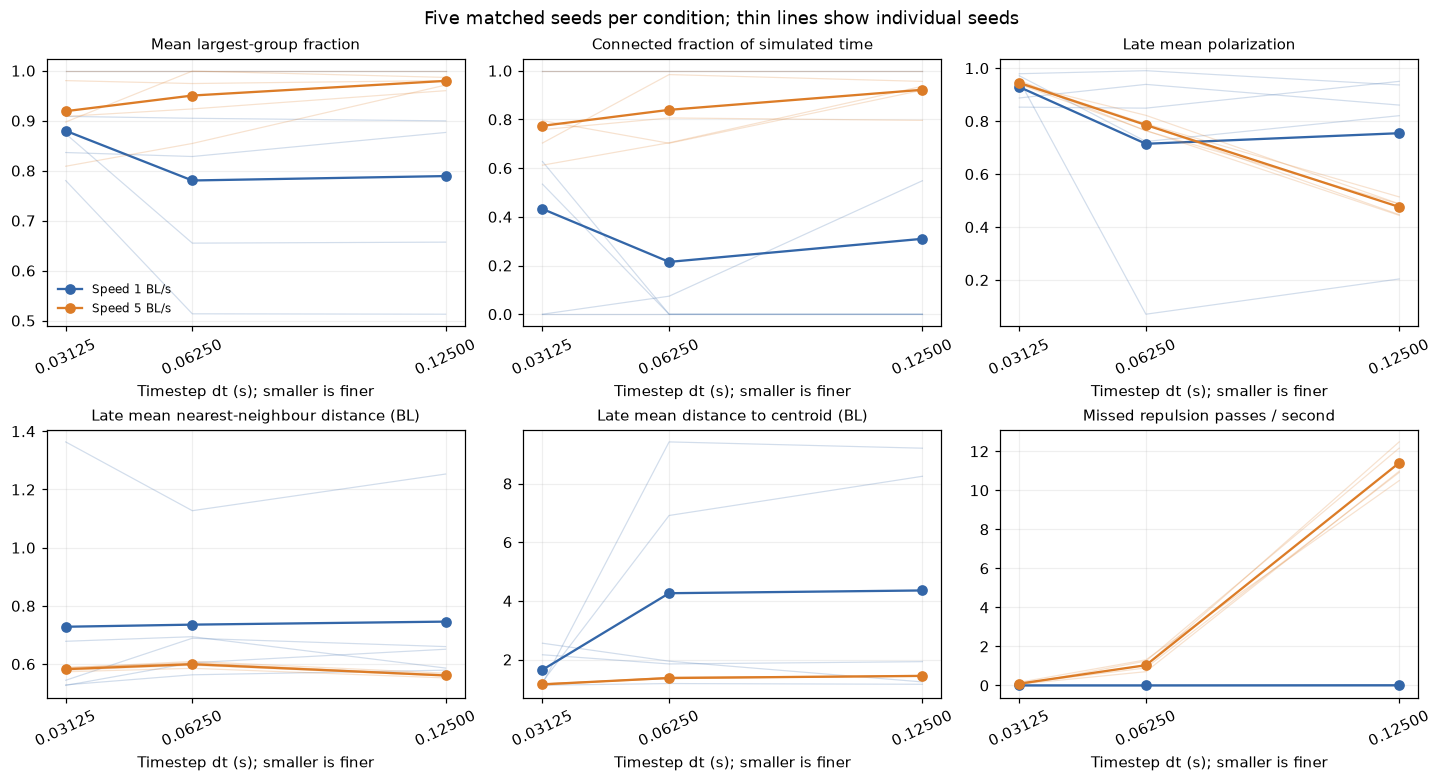

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
plot_metrics = [
    ("MeanLargestGroupFraction", "Mean largest-group fraction"),
    ("ConnectedTimeFraction", "Connected fraction of simulated time"),
    ("LatePolarization", "Late mean polarization"),
    ("LateMeanNND", "Late mean nearest-neighbour distance (BL)"),
    ("LateMeanDistanceToCentroid", "Late mean distance to centroid (BL)"),
    ("MissedPassesPerSecond", "Missed repulsion passes / second"),
]
for axis, (metric, title) in zip(axes.flat, plot_metrics):
    for speed, color in [(1.0, "#3366a8"), (5.0, "#dc7c27")]:
        selected = timestep_summary.loc[timestep_summary["Speed_BL_s"].eq(speed)]
        for seed in SEEDS:
            trajectory = selected.loc[selected["Seed"].eq(seed)].sort_values("Dt_s")
            axis.plot(trajectory["Dt_s"], trajectory[metric], color=color, alpha=0.22, linewidth=0.8)
        means = selected.groupby("Dt_s")[metric].mean().sort_index()
        axis.plot(means.index, means, "o-", color=color, label=f"Speed {speed:g} BL/s")
    axis.set_title(title, fontsize=10)
    axis.set_xlabel("Timestep dt (s); smaller is finer")
    axis.set_xticks(sorted(DTS))
    axis.tick_params(axis="x", rotation=25)
    axis.grid(alpha=0.2)
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Five matched seeds per condition; thin lines show individual seeds")
fig.savefig(FIGURE_DIR / "04_timestep_condition_summary.png", dpi=180)
plt.show()

## Compare trajectories on a common physical-time grid

For each seed and speed, compare the 0.125 and 0.0625 s trajectories with the finest tested trajectory (`dt=0.03125 s`). Both comparisons use exactly the **same 0.125 s physical-time grid**, including t=0, so a difference in the comparison statistic is not caused by different sampling times. No interpolation is needed for these binary-fraction timesteps.

The finest tested run is a reference, not known ground truth. Lower differences for the middle timestep would be consistent with improving agreement, but three timestep values cannot establish an asymptotic convergence order, and changing dt also changes instantaneous social decision frequency.

In [5]:
COMMON_DT = max(DTS)
REFERENCE_DT = min(DTS)
comparison_metrics = ["LargestGroupFraction", "NumberOfGroups", "Polarization", "MeanNND", "MeanDistanceToCentroid"]
grid_rows = []
for seed in SEEDS:
    for speed in SPEEDS:
        reference = timestep_frames[(seed, speed, REFERENCE_DT)].set_index("Time")
        common_times = np.arange(round(DURATION/COMMON_DT)+1)*COMMON_DT
        reference_common = reference.loc[common_times, comparison_metrics]
        for candidate_dt in [0.125, 0.0625]:
            candidate = timestep_frames[(seed, speed, candidate_dt)].set_index("Time")
            candidate_common = candidate.loc[common_times, comparison_metrics]
            assert len(candidate_common) == len(reference_common) == 251
            difference = candidate_common-reference_common
            row = {"Seed": seed, "Speed_BL_s": speed, "CandidateDt_s": candidate_dt,
                   "ReferenceDt_s": REFERENCE_DT, "CommonSamplingDt_s": COMMON_DT,
                   "ComparedRecords": len(common_times)}
            for metric in comparison_metrics:
                row[f"{metric}_MAE"] = difference[metric].abs().mean()
                row[f"{metric}_RMSE"] = np.sqrt(np.mean(difference[metric]**2))
            grid_rows.append(row)
grid_comparison = pd.DataFrame(grid_rows)
grid_comparison.to_csv(DATA_DIR / "04_timestep_grid_differences.csv", index=False)
grid_comparison.groupby(["Speed_BL_s", "CandidateDt_s"])[[
    "LargestGroupFraction_MAE", "NumberOfGroups_MAE", "Polarization_RMSE",
    "MeanNND_RMSE", "MeanDistanceToCentroid_RMSE",
]].mean().round(5)

LargestGroupFraction_MAE  NumberOfGroups_MAE  \
Speed_BL_s CandidateDt_s                                                 
1.0        0.0625                          0.10271             0.26135   
           0.1250                          0.11367             0.36255   
5.0        0.0625                          0.03450             0.11076   
           0.1250                          0.06295             0.16016   

                          Polarization_RMSE  MeanNND_RMSE  \
Speed_BL_s CandidateDt_s                                    
1.0        0.0625                   0.27911       0.11290   
           0.1250                   0.26430       0.09438   
5.0        0.0625                   0.27541       0.09144   
           0.1250                   0.46264       0.11033   

                          MeanDistanceToCentroid_RMSE  
Speed_BL_s CandidateDt_s                               
1.0        0.0625                             2.39698  
           0.1250                             2.53500  
5.0        0.0625                             1.44457  
           0.1250                             1.94349

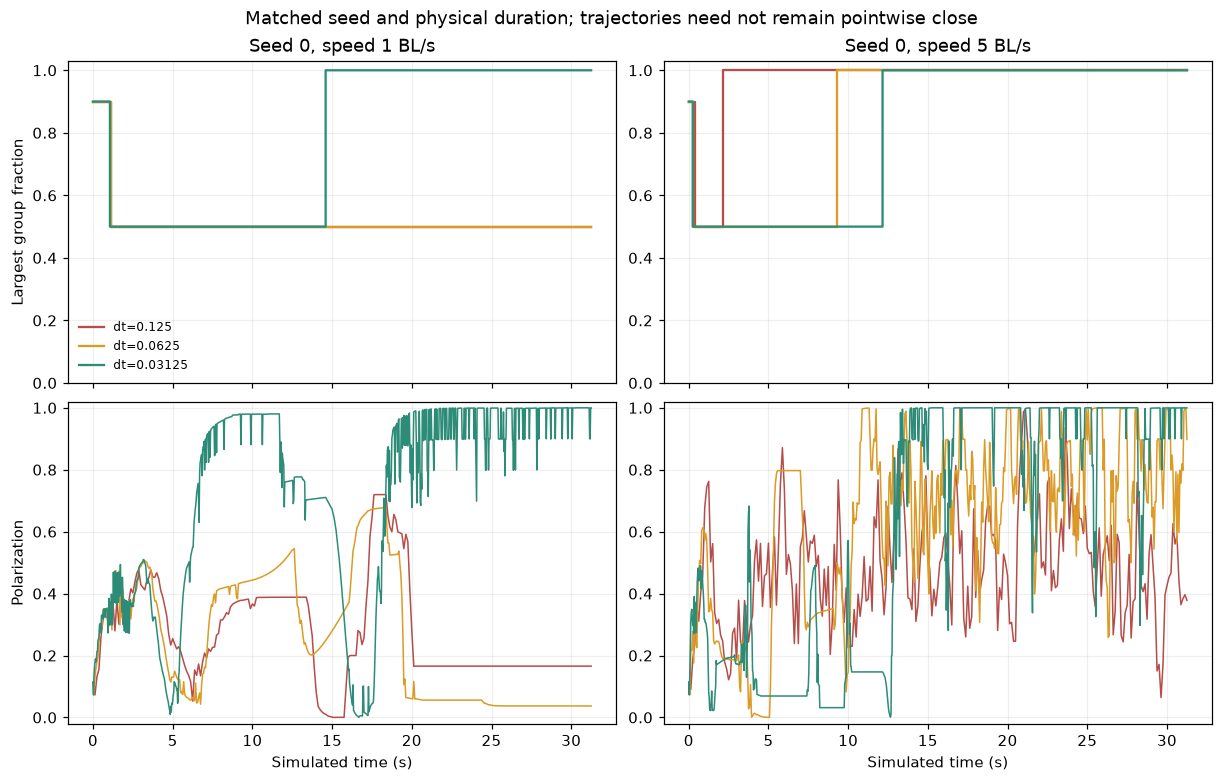

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, constrained_layout=True)
colors = {0.125: "#b54d49", 0.0625: "#dc9b27", 0.03125: "#2c8c78"}
for column, speed in enumerate(SPEEDS):
    for dt in DTS:
        frame = timestep_frames[(0, speed, dt)]
        axes[0, column].step(frame["Time"], frame["LargestGroupFraction"], where="post", label=f"dt={dt:g}", color=colors[dt])
        axes[1, column].plot(frame["Time"], frame["Polarization"], color=colors[dt], linewidth=1)
    axes[0, column].set_title(f"Seed 0, speed {speed:g} BL/s")
    axes[0, column].set_ylim(0, 1.03)
    axes[1, column].set_ylim(-0.02, 1.02)
    axes[1, column].set_xlabel("Simulated time (s)")
    for row in range(2):
        axes[row, column].grid(alpha=0.2)
axes[0, 0].set_ylabel("Largest group fraction")
axes[1, 0].set_ylabel("Polarization")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Matched seed and physical duration; trajectories need not remain pointwise close")
fig.savefig(FIGURE_DIR / "04_matched_seed_timestep_traces.png", dpi=180)
plt.show()

## A controlled missed-zone encounter

This two-fish probe isolates the sampling problem: speed 5 BL/s, initial separation 0.7 BL, opposite headings, no nearby wall, and **repulsion only**. Orientation and attraction are disabled only in this diagnostic so another rule cannot turn the fish before the encounter. The same 0.125 s physical interval is tested with 1, 2 or 4 updates.

At the coarse step, each fish travels 0.625 BL and the pair can exchange sides without either sampled separation lying inside the repulsion zone. At finer steps, the close encounter can be observed and repulsion can act. This is a controlled resolution example, not a substitute for the full-model multi-seed rates above.

In [7]:
probe_rows = []
for dt in DTS:
    probe_model, probe_frame, probe_agents = run_case(
        seed=123, n_fish=2, duration=0.125, speed=5.0, dt=dt,
        initial_state=(np.array([[9.65, 10], [10.35, 10]]), np.array([[1, 0], [-1, 0]])),
        enabled_rules=("repulsion",),
    )
    final_positions = probe_agents.xs(probe_model.steps, level="Step")[["X", "Y"]].to_numpy()
    missed = int(probe_frame["MissedRepulsionPasses"].sum())
    exchanged_sides = bool(final_positions[0, 0] > final_positions[1, 0])
    if dt == 0.125:
        assert missed == 1 and exchanged_sides
    else:
        assert missed == 0 and not exchanged_sides
    probe_rows.append({"Dt_s": dt, "Updates": probe_model.steps,
                       "MissedRepulsionPasses": missed, "ExchangedSides": exchanged_sides,
                       "MinimumRecordedDistance_BL": probe_frame["MinimumPairDistance"].min()})
probe_results = pd.DataFrame(probe_rows)
probe_results.to_csv(DATA_DIR / "04_controlled_zone_crossing.csv", index=False)
probe_results

,Dt_s,Updates,MissedRepulsionPasses,ExchangedSides,MinimumRecordedDistance_BL
0,0.12500,1,1,True,0.5500
1,0.06250,2,0,False,0.0750
2,0.03125,4,0,False,0.3875


In [8]:
condition_means = timestep_summary.groupby(["Speed_BL_s", "Dt_s"]).mean(numeric_only=True)
interpretation_lines = []
for speed in SPEEDS:
    coarse = condition_means.loc[(speed, 0.125)]
    fine = condition_means.loc[(speed, 0.03125)]
    interpretation_lines.append(
        f"- Speed {speed:g} BL/s: mean missed passes **{coarse['MissedPassesPerSecond']:.3f}/s → {fine['MissedPassesPerSecond']:.3f}/s** from dt=0.125 to 0.03125. Mean largest-group fraction changes **{coarse['MeanLargestGroupFraction']:.3f} → {fine['MeanLargestGroupFraction']:.3f}** and connected-time fraction **{coarse['ConnectedTimeFraction']:.3f} → {fine['ConnectedTimeFraction']:.3f}**."
    )
error_means = grid_comparison.groupby(["Speed_BL_s", "CandidateDt_s"]).mean(numeric_only=True)
for speed in SPEEDS:
    coarse_error = error_means.loc[(speed, 0.125), "LargestGroupFraction_MAE"]
    middle_error = error_means.loc[(speed, 0.0625), "LargestGroupFraction_MAE"]
    interpretation_lines.append(
        f"- On the common grid at speed {speed:g}, largest-group-fraction MAE against the finest run is **{coarse_error:.3f}** for dt=0.125 and **{middle_error:.3f}** for dt=0.0625. Other metric differences are shown above; improvements need not be monotonic for every metric."
    )
interpretation_text = "\n".join(interpretation_lines)
overlap_fraction_max = timestep_summary["OverlapTimeFraction"].max()
display(Markdown(f"""## Interpretation of the executed experiment

{interpretation_text}

The maximum observed exact-overlap time fraction is **{overlap_fraction_max:.4f}**. Absence of recorded exact overlap does not remove missed-zone encounters: the controlled head-on probe misses one whole encounter at dt=0.125 while the finer steps observe the repulsion zone. Recorded overlap and between-update interaction resolution are different questions.

At 5 BL/s, the coarse run can appear **more connected** while having a much larger missed-zone rate. Choosing dt solely for a visually cohesive trajectory would therefore select on an outcome that may be affected by unresolved interactions. The finest timestep substantially reduces missed passes, but the remaining rate and trajectory differences do not establish timestep independence or a continuum limit.

All recorded states remain finite and inside the arena. That numerical boundedness is weaker than adequate interaction resolution. Pointwise differences can reflect discrete decision frequency, long-term sensitivity and unsampled encounters. This 31.25 s comparison does not establish the 62.5 s fragmentation frequency.

No parameter was tuned for a visually appealing school. A future turning limit or angular noise needs an explicit physical-time/per-update scaling convention before this comparison is repeated; neither is active here. No light stage has been implemented.
"""))

## Interpretation of the executed experiment

- Speed 1 BL/s: mean missed passes **0.006/s → 0.000/s** from dt=0.125 to 0.03125. Mean largest-group fraction changes **0.789 → 0.880** and connected-time fraction **0.310 → 0.432**.
- Speed 5 BL/s: mean missed passes **11.405/s → 0.090/s** from dt=0.125 to 0.03125. Mean largest-group fraction changes **0.980 → 0.919** and connected-time fraction **0.922 → 0.774**.
- On the common grid at speed 1, largest-group-fraction MAE against the finest run is **0.114** for dt=0.125 and **0.103** for dt=0.0625. Other metric differences are shown above; improvements need not be monotonic for every metric.
- On the common grid at speed 5, largest-group-fraction MAE against the finest run is **0.063** for dt=0.125 and **0.035** for dt=0.0625. Other metric differences are shown above; improvements need not be monotonic for every metric.

The maximum observed exact-overlap time fraction is **0.0000**. Absence of recorded exact overlap does not remove missed-zone encounters: the controlled head-on probe misses one whole encounter at dt=0.125 while the finer steps observe the repulsion zone. Recorded overlap and between-update interaction resolution are different questions.

At 5 BL/s, the coarse run can appear **more connected** while having a much larger missed-zone rate. Choosing dt solely for a visually cohesive trajectory would therefore select on an outcome that may be affected by unresolved interactions. The finest timestep substantially reduces missed passes, but the remaining rate and trajectory differences do not establish timestep independence or a continuum limit.

All recorded states remain finite and inside the arena. That numerical boundedness is weaker than adequate interaction resolution. Pointwise differences can reflect discrete decision frequency, long-term sensitivity and unsampled encounters. This 31.25 s comparison does not establish the 62.5 s fragmentation frequency.

No parameter was tuned for a visually appealing school. A future turning limit or angular noise needs an explicit physical-time/per-update scaling convention before this comparison is repeated; neither is active here. No light stage has been implemented.
